# Key-Rate Limits and the Liquidity Cost of Hedging in R: A Bank Treasury Book under the Basel IRRBB Shocks and Forty Years of Curve Twists, Bucket and PCA Limits, Minimum-Cost Swap Hedges, Margin Calls and XGBoost Forecasts

A bank treasury reports a net DV01 of zero after paying fixed on an interest-rate swap, and its aggregate DV01 limit is met. Below the total, the balance sheet is long the 10- to 30-year part of the curve (mortgages and bonds) and short the 1- to 7-year part (core deposits and the hedge). The treasury has three choices: **A**, accept the residual curve risk; **B**, move the hedge to where the risk is; **C**, hedge each key-rate bucket. Each choice has a cost in bid-ask spread and in collateral: swaps are cleared and margined every day, while the loans and deposits they hedge are not.

This notebook puts numbers on that decision for a stylised 10-billion-dollar balance sheet:

1. **key-rate DV01s** of every balance-sheet item, priced on today's Treasury zero curve;
2. the **six Basel IRRBB interest-rate shocks** for US dollars and the supervisory outlier test (a loss of economic value above 15% of Tier 1 capital), against **one-year curve moves since 1986**;
3. three **limit structures** (aggregate DV01, key-rate buckets, principal components) and how each judges the same book;
4. **four hedges**: DV01-neutral with a 5-year swap, DV01-neutral with a 10-year swap, level-and-slope neutral with two swaps, and the **cheapest set of swaps that meets every limit** (a linear programme);
5. the **liquidity cost** of each hedge: initial margin, variation-margin outflows over a month and a quarter, and the buffer needed;
6. **XGBoost quantile forecasts** of next-month margin calls against historical and EWMA benchmarks.

The notebook is written in **R** (data.table, httr2, ggplot2, lpSolve and xgboost).

**Data.** Federal Reserve Board: the Gürkaynak–Sack–Wright Treasury yield curve (daily Svensson parameters); FRED: effective federal funds rate. The balance sheet is synthetic.

**Methods.** Svensson zero curve; cash-flow ladders for loans, mortgages (with constant prepayment), securities, deposits and debt; key-rate (tent) DV01s; economic value of equity (EVE) under the six Basel shocks with the post-shock floor; historical simulation of one-year key-rate moves; principal component analysis; DV01, factor-neutral and linear-programming hedges; initial margin as a 99.7% five-day historical VaR; variation-margin distributions; XGBoost quantile regression with yearly expanding windows; Kupiec and Christoffersen tests; pinball loss.

**Key output.** Key-rate DV01 ladder by item; ΔEVE by Basel shock and hedge; historical ΔEVE quantiles; limit compliance by structure and hedge; swap notionals and transaction cost; initial margin, month and quarter margin outflows and liquidity buffer; forecast coverage and losses.

## 1. Fundamentals

**Economic value of equity.** EVE is the present value of asset cash flows minus that of liability cash flows, discounted on the risk-free curve. The Basel standard on interest rate risk in the banking book (IRRBB, BCBS 2016) measures $\Delta\text{EVE}$ under six prescribed shocks and treats a bank as an **outlier** when the worst loss exceeds 15% of Tier 1 capital.

**The six shocks** for US dollars use a parallel shock $\bar R_p = 200$ bp, a short shock $\bar R_s = 300$ bp and a long shock $\bar R_l = 150$ bp, with
$$S(t) = \bar R_s e^{-t/4}, \qquad L(t) = \bar R_l\,(1-e^{-t/4}),$$
- parallel up and down: $\pm \bar R_p$;
- short up and down: $\pm S(t)$;
- steepener: $-0.65\,S(t) + 0.9\,L(t)$;
- flattener: $+0.8\,S(t) - 0.6\,L(t)$.

After a shock, rates are floored at −100 bp for the shortest maturities, rising by 5 bp a year to 0% at 20 years (the floor never lifts a rate above where it started).

**Key-rate DV01s.** A 1 bp tent shift at key rate $k_j$ (1 at $k_j$, linear to 0 at the neighbouring key rates) measures the bucket sensitivity $\text{KR}_j$, and $\Delta\text{EVE} \approx -\sum_j \text{KR}_j\,\Delta y_j$. The aggregate DV01 is $\sum_j \text{KR}_j$.

**Limit structures.**

| Structure | Limit | Blind spot |
|---|---|---|
| Aggregate DV01 | $\lvert \sum_j \text{KR}_j \rvert \le$ limit | offsetting buckets |
| Key-rate buckets | $\lvert \text{KR}_j \rvert \le$ limit for each $j$ | correlation between buckets |
| Principal components | $\lvert \text{KR}^\top \ell_k \rvert \le$ limit for $k=1,2,3$ | rare shapes outside three factors |
| Basel EVE | $\min_s \Delta\text{EVE}_s \ge -15\%$ of Tier 1 | only six shapes |

**The cheapest hedge that meets the limits.** With swap DV01s $n_i$ (receiver positive) and key-rate profiles $u_{ij}$ per dollar of DV01, the linear programme
$$\min_{n} \sum_i c_i \lvert n_i\rvert \quad \text{s.t.}\quad \Big\lvert \text{KR}_j + \sum_i u_{ij} n_i \Big\rvert \le L_j \ \forall j, \qquad -\sum_j \Big(\text{KR}_j + \sum_i u_{ij} n_i\Big) s_{kj} \ge -0.15\,\text{T1}\ \forall k$$
minimises the bid-ask cost $c_i$ (bp per unit of DV01). The same linear form adds the aggregate limit $\lvert \sum_j (\text{KR}_j + \sum_i u_{ij} n_i)\rvert \le L$ and the principal-component limits $\lvert \ell_k^\top(\text{KR} + u\,n)\rvert \le L_k$. Absolute values are handled by splitting $n_i = n_i^+ - n_i^-$.

**Margin.** A cleared swap pays and receives **variation margin** equal to its daily change in value; the hedged loans and deposits are held at cost and produce no cash. A hedge that offsets the economic value of the book can therefore drain cash when rates move against it. The clearing house also requires **initial margin**; here it is approximated by a 99.7% five-day historical VaR over the last ten years plus the 2008 stress period. The **liquidity buffer** for a hedge is initial margin plus the 99% month-ahead variation-margin outflow.

## 2. Setup

In [12]:
# --- Packages (install once with install.packages(); versions are printed below) -----------------
suppressPackageStartupMessages({
  library(data.table)
  library(ggplot2)
  library(httr2)
  library(jsonlite)
  library(lpSolve)
  library(xgboost)
  library(patchwork)
  library(scales)
})
if (!isTRUE(l10n_info()[["UTF-8"]])) invisible(Sys.setlocale("LC_CTYPE", "C.UTF-8"))   # Unicode in tables and charts
options(jupyter.plot_mimetypes = "image/png", bitmapType = if (isTRUE(capabilities("cairo"))) "cairo" else getOption("bitmapType"))
options(warn = 1, width = 160, scipen = 6, datatable.print.class = FALSE, repr.plot.width = 15, repr.plot.height = 9)

# --- Folders and credentials (.env at the repo root, never printed) -----------------------------
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR, "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR, showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
find_env <- function(dir = PROJECT_DIR) {
  repeat {
    f <- file.path(dir, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(dir)
    if (parent == dir) return(NA_character_)
    dir <- parent
  }
}
env_file <- find_env()
if (!is.na(env_file)) readRenviron(env_file)
FRED_API_KEY <- trimws(Sys.getenv("FRED_API_KEY"))
if (!nzchar(FRED_API_KEY)) stop("FRED_API_KEY not found. Create the .env file at the repo root (see .env.example).")

BROWSER_UA <- "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0 Safari/537.36"
YAHOO_UA <- "Mozilla/5.0"          # Yahoo throttles fuller browser strings from scripts

SEED <- 2026; set.seed(SEED)
GSW_URL <- "https://www.federalreserve.gov/data/yield-curve-tables/feds200628.csv"
NODES <- c(0.25, 1, 2, 3, 5, 7, 10, 15, 20, 30)   # key rates (years)
TIER1 <- 900                  # million dollars of Tier 1 capital
OUTLIER <- 0.15               # Basel supervisory outlier threshold (share of Tier 1)
BASEL_USD <- c(parallel = 200, short = 300, long = 150)   # bp
LIM_AGG <- 250000             # aggregate DV01 limit (dollars per bp)
LIM_BUCKET <- 250000          # key-rate bucket limit (dollars per bp, each bucket)
LIM_PC <- c(250000, 150000, 100000)   # limits on exposure to principal components 1-3 (dollars per unit of loading per bp)
SWAPS <- c(2, 5, 10, 20, 30)  # hedge instruments: par interest-rate swaps (years)
COST_BP <- c(0.10, 0.10, 0.15, 0.20, 0.25)   # half bid-ask (bp of DV01) per swap
HIST_FROM <- as.IDate("1985-11-25")   # first day with a 30-year zero yield
IM_DAYS <- 5; IM_Q <- 0.997; IM_YEARS <- 10
H <- 21                       # margin forecast horizon (trading days)
ML_START <- 1995
ALPHAS <- c(0.95, 0.99)
EWMA_LAMBDA <- 0.97

cat(sprintf("%s · %s · run on %s\n", R.version.string,
            paste(sprintf("%s %s", c("data.table", 'lpSolve', 'xgboost', 'patchwork', 'scales'),
                          sapply(c("data.table", 'lpSolve', 'xgboost', 'patchwork', 'scales'), function(p) as.character(packageVersion(p)))), collapse = " · "),
            Sys.Date()))

R version 4.6.1 (2026-06-24) · data.table 1.18.6.1 · lpSolve 5.6.23 · xgboost 3.2.1.1 · patchwork 1.3.2 · scales 1.4.0 · run on 2026-11-18


In [13]:
# --- Caching helper: every download is stored in data/ and reused for max_age_hours ------------
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  fresh <- file.exists(path) && as.numeric(difftime(Sys.time(), file.mtime(path), units = "hours")) < max_age_hours
  if (fresh) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) e)
  if (inherits(out, "error")) {
    if (file.exists(path)) {
      message(sprintf("%s: download failed (%s); using cached copy", name, conditionMessage(out)))
      return(readRDS(path))
    }
    stop(out)
  }
  saveRDS(out, path)
  out
}

# FRED series as a data.table(date, value)
fred_series <- function(id, start = "1990-01-01") {
  resp <- request("https://api.stlouisfed.org/fred/series/observations") |>
    req_url_query(series_id = id, api_key = FRED_API_KEY, file_type = "json", observation_start = start) |>
    req_retry(max_tries = 4) |> req_perform()
  obs <- resp_body_json(resp, simplifyVector = TRUE)$observations
  data.table(date = as.IDate(obs$date), value = suppressWarnings(as.numeric(obs$value)))[!is.na(value)]
}

# --- Chart style (same palette as the Python notebooks) ------------------------------------------
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
theme_lab <- function() {
  theme_minimal(base_size = 12) +
    theme(plot.background = element_rect(fill = SURFACE, colour = NA), panel.background = element_rect(fill = SURFACE, colour = NA),
          panel.grid.minor = element_blank(), panel.grid.major = element_line(colour = GRID),
          plot.title = element_text(face = "bold", colour = INK, hjust = 0), axis.text = element_text(colour = INK_2),
          axis.title = element_text(colour = INK_2), legend.position = "bottom", legend.title = element_blank())
}
theme_set(theme_lab())
save_fig <- function(p, name, width = 15, height = 9) ggsave(file.path(OUT_DIR, paste0(name, ".png")), p, width = width, height = height, dpi = 150, bg = SURFACE)
# Save a chart and show the saved PNG: the notebook displays exactly the file in outputs/, on any operating system
show_fig <- function(p, name, width = 15, height = 9) {
  save_fig(p, name, width, height)
  IRdisplay::display_png(file = file.path(OUT_DIR, paste0(name, ".png")))
}
show_table <- function(x, digits = 2) {
  x <- as.data.frame(x)
  num <- vapply(x, is.numeric, logical(1))
  x[num] <- lapply(x[num], round, digits)
  print(x, row.names = FALSE)
  invisible(x)
}

## 3. Data and the balance sheet

The Treasury zero curve comes from the Gürkaynak–Sack–Wright Svensson parameters (continuously compounded yields). The history used for scenarios starts in November 1985, the first day the Board publishes a 30-year point.

The balance sheet (million dollars of notional) is stylised but typical of a regional bank:

| Assets | | Liabilities | |
|---|---|---|---|
| Cash and reserves (overnight) | 500 | Non-core deposits (overnight) | 2,400 |
| Floating-rate loans (3-month reset) | 3,000 | Core deposits (behavioural run-off over 1–7 years) | 3,600 |
| Corporate loans, 5-year fixed 6.5% | 1,500 | Term deposits, 1-year 4.2% | 1,500 |
| Residential mortgages, 30-year fixed 6.5%, 8% CPR | 2,500 | Senior debt, 5-year fixed 5.5% | 1,000 |
| Treasury notes, 2-year 4.5% | 800 | | |
| Treasury bonds, 10-year 4.8% | 1,200 | Tier 1 capital | 900 |

Cash flows include contractual coupons, discounted on the Treasury zero curve as the Basel standard allows; the floating-rate loans count only to their next reset.

In [14]:
fetch_gsw <- function() {
  txt <- request(GSW_URL) |> req_user_agent(BROWSER_UA) |> req_timeout(300) |> req_retry(max_tries = 3) |> req_perform() |> resp_body_string()
  lines <- strsplit(txt, "\n", fixed = TRUE)[[1]]
  fread(text = paste(lines[grep("^Date", lines)[1]:length(lines)], collapse = "\n"))
}
RAW <- cached("gsw_curve", fetch_gsw, max_age_hours = 24 * 7)
G <- RAW[, .(date = as.IDate(Date), b0 = BETA0, b1 = BETA1, b2 = BETA2, b3 = BETA3, t1 = TAU1, t2 = TAU2, y2 = SVENY02, y10 = SVENY10, y30 = SVENY30)][
  !is.na(b0) & date >= HIST_FROM & !is.na(y30)]
setkey(G, date)
sv <- function(tm, d) {
  f1 <- function(x, tau) (1 - exp(-x / tau)) / (x / tau)
  t2 <- ifelse(d$t2 > 0, d$t2, 1); b3 <- ifelse(d$t2 > 0 & !is.na(d$b3), d$b3, 0)
  d$b0 + d$b1 * f1(tm, d$t1) + d$b2 * (f1(tm, d$t1) - exp(-tm / d$t1)) + b3 * (f1(tm, t2) - exp(-tm / t2))
}
ZN <- sv(matrix(NODES, nrow(G), length(NODES), byrow = TRUE), G)       # zero yields at key rates, % (days x nodes)
colnames(ZN) <- paste0(NODES, "y")
LAST <- G[.N]; zc <- function(t) sv(t, LAST)

items <- list()
add <- function(item, side, t, cf) items[[length(items) + 1]] <<- data.table(item = item, side = side, t = t, cf = cf)
bullet <- function(item, side, N, cpn, T, freq = 2) { t <- seq(1 / freq, T, by = 1 / freq); add(item, side, t, N * cpn / freq + c(rep(0, length(t) - 1), N)) }
mortgage <- function(item, N, r, T, cpr) {
  m <- 1:(T * 12); i <- r / 12; smm <- 1 - (1 - cpr)^(1 / 12); bal <- N; out <- numeric(length(m))
  for (k in m) { n <- T * 12 - k + 1; pay <- bal * i / (1 - (1 + i)^-n); sch <- pay - bal * i; pre <- (bal - sch) * smm; out[k] <- pay + pre; bal <- bal - sch - pre }
  add(item, "asset", m / 12, out)
}
add("cash and reserves", "asset", 1 / 365, 500)
add("floating-rate loans", "asset", 0.25, 3000)
bullet("corporate loans (5y fixed)", "asset", 1500, 0.065, 5)
mortgage("residential mortgages (30y fixed)", 2500, 0.065, 30, 0.08)
bullet("Treasury notes (2y)", "asset", 800, 0.045, 2)
bullet("Treasury bonds (10y)", "asset", 1200, 0.048, 10)
add("non-core deposits", "liability", 1 / 365, 2400)
add("core deposits", "liability", 1:7, rep(3600 / 7, 7))
bullet("term deposits (1y)", "liability", 1500, 0.042, 1, 1)
bullet("senior debt (5y fixed)", "liability", 1000, 0.055, 5)
CF <- rbindlist(items); CF[, sg := ifelse(side == "asset", 1, -1)]

tent_w <- function(t) matrix(sapply(seq_along(NODES), function(j) {
  k <- NODES
  vapply(t, function(x) {
    if (x <= k[1]) return(as.numeric(j == 1)); if (x >= k[length(k)]) return(as.numeric(j == length(k)))
    lo <- max(which(k <= x)); a <- (x - k[lo]) / (k[lo + 1] - k[lo]); if (j == lo) 1 - a else if (j == lo + 1) a else 0
  }, numeric(1))
}), nrow = length(t))
W_CF <- tent_w(CF$t)                         # cash flows x nodes
pv_cf <- function(t, cf, shift = 0) cf * exp(-(zc(t) + shift) / 100 * t)
kr_of <- function(t, cf, W) sapply(seq_along(NODES), function(j) sum(1e6 * (pv_cf(t, cf, -W[, j] * 0.01) - pv_cf(t, cf, W[, j] * 0.01)) / 2))
LADDER <- CF[, as.list(setNames(kr_of(t, cf * sg, tent_w(t)), paste0(NODES, "y"))), by = item]
KR0 <- colSums(LADDER[, -1])
EVE0 <- sum(pv_cf(CF$t, CF$cf * CF$sg))
cat(sprintf("Curve on %s: 3-month %.2f%%, 2-year %.2f%%, 10-year %.2f%%, 30-year %.2f%%. EVE %.0f million dollars; aggregate DV01 %s dollars per bp\n",
            format(LAST$date), zc(0.25), zc(2), zc(10), zc(30), EVE0, format(round(sum(KR0)), big.mark = ",")))
show_table(rbind(LADDER, data.table(item = "balance sheet", t(KR0)), use.names = FALSE), 0)

Curve on 2026-11-13: 3-month 4.29%, 2-year 4.83%, 10-year 5.14%, 30-year 5.51%. EVE 1849 million dollars; aggregate DV01 1,828,433 dollars per bp
                              item 0.25y      1y     2y      3y      5y      7y     10y    15y    20y   30y
                 cash and reserves   137       0      0       0       0       0       0      0      0     0
               floating-rate loans 74199       0      0       0       0       0       0      0      0     0
        corporate loans (5y fixed)  1589    8854  17652   41203  630057       0       0      0      0     0
 residential mortgages (30y fixed)  8140   32239  60145  124392  196713  258458  365110 328288 245075 81787
               Treasury notes (2y)   587    3269 149796       0       0       0       0      0      0     0
              Treasury bonds (10y)   939    5231  10428   24342   44765   72729  775869      0      0     0
                 non-core deposits  -657       0      0       0       0       0       0      0    

## 4. Hedge instruments and the four hedges

Each hedge uses cleared par swaps, priced (as an approximation) on the Treasury zero curve so that a receiver swap has the key-rate profile of a par bond. The hedges:

- **A. DV01-neutral, 5-year payer** — the conventional choice: pay fixed on the 5-year swap until the aggregate DV01 is zero;
- **B. DV01-neutral, 10-year payer** — the same aggregate, with the swap placed where the assets sit;
- **C. level and slope** — a 5-year and a 20-year swap sized so the book has no exposure to the first two principal components of daily curve changes since 1986;
- **D. minimum cost** — the linear programme of section 1, choosing among 2-, 5-, 10-, 20- and 30-year swaps the cheapest DV01s that bring the aggregate DV01, every bucket and every principal-component exposure within their limits and every Basel shock within the outlier threshold.

In [15]:
par_cpn <- function(T) { t <- seq(0.5, T, 0.5); df <- exp(-zc(t) / 100 * t); 2 * (1 - df[length(df)]) / sum(df) }
SW <- lapply(SWAPS, function(T) { t <- seq(0.5, T, 0.5); c <- par_cpn(T); data.table(t = t, cf = c / 2 + c(rep(0, length(t) - 1), 1)) })
U1 <- sapply(SW, function(d) kr_of(d$t, d$cf, tent_w(d$t)))       # key-rate DV01s per 1 million notional of receiver swap
DV1 <- colSums(U1); U <- sweep(U1, 2, DV1, "/")                   # per dollar of swap DV01
colnames(U) <- paste0(SWAPS, "y swap")

DYN <- 100 * apply(ZN, 2, diff)                                  # daily key-rate changes (bp)
PCA <- prcomp(DYN, center = TRUE); PCL <- PCA$rotation[, 1:3]
PCL <- sweep(PCL, 2, sign(PCL["30y", ]), "*")

hedge_A <- c(0, -sum(KR0) / sum(U[, 2]), 0, 0, 0)
hedge_B <- c(0, 0, -sum(KR0) / sum(U[, 3]), 0, 0)
Mpc <- t(PCL[, 1:2]) %*% U[, c(2, 4)]; hedge_C <- c(0, 0, 0, 0, 0); hedge_C[c(2, 4)] <- solve(Mpc, -t(PCL[, 1:2]) %*% KR0)

basel_shift <- function(t, s) {   # bp, with the post-shock floor
  S <- BASEL_USD["short"] * exp(-t / 4); L <- BASEL_USD["long"] * (1 - exp(-t / 4))
  raw <- switch(s, "parallel up" = rep(BASEL_USD["parallel"], length(t)), "parallel down" = rep(-BASEL_USD["parallel"], length(t)),
                "steepener" = -0.65 * S + 0.9 * L, "flattener" = 0.8 * S - 0.6 * L, "short up" = S, "short down" = -S)
  floor_ <- pmin(-100 + 5 * t, 0); z <- 100 * zc(t)
  unname(pmax(z + raw, pmin(floor_, z)) - z)
}
SHOCKS <- c("parallel up", "parallel down", "steepener", "flattener", "short up", "short down")
SNODE <- sapply(SHOCKS, function(s) basel_shift(NODES, s))       # nodes x shocks (bp)
COST <- c(COST_BP)
nv <- length(SWAPS)
one <- matrix(1, 1, length(NODES)); PU <- t(PCL) %*% U; pk <- as.vector(t(PCL) %*% KR0)
A_lp <- rbind(cbind(U, -U), cbind(U, -U), t(SNODE) %*% cbind(-U, U),
              one %*% cbind(U, -U), one %*% cbind(U, -U), cbind(PU, -PU), cbind(PU, -PU))
rhs <- c(LIM_BUCKET - KR0, -LIM_BUCKET - KR0, -OUTLIER * TIER1 * 1e6 + as.vector(t(SNODE) %*% KR0),
         LIM_AGG - sum(KR0), -LIM_AGG - sum(KR0), LIM_PC - pk, -LIM_PC - pk)
dirs <- c(rep("<=", length(NODES)), rep(">=", length(NODES)), rep(">=", length(SHOCKS)), "<=", ">=", rep("<=", 3), rep(">=", 3))
LP <- lp("min", c(COST, COST), A_lp, dirs, rhs)
hedge_D <- LP$solution[1:nv] - LP$solution[(nv + 1):(2 * nv)]

HEDGES <- list(`unhedged` = rep(0, nv), `A. 5y DV01-neutral` = hedge_A, `B. 10y DV01-neutral` = hedge_B,
               `C. level and slope (5y + 20y)` = hedge_C, `D. minimum cost within limits` = hedge_D)
HTAB <- rbindlist(lapply(names(HEDGES), function(h) { n <- HEDGES[[h]]
  data.table(hedge = h, t(setNames(round(n), paste0(SWAPS, "y DV01"))), `notional (million)` = sum(abs(n / DV1)), `bid-ask cost (dollars)` = sum(COST * abs(n)))
}))
cat(sprintf("Linear programme status %d (0 = optimal). Swap DV01s in dollars per bp (negative = pay fixed):\n", LP$status))
show_table(HTAB, 0)

Linear programme status 0 (0 = optimal). Swap DV01s in dollars per bp (negative = pay fixed):
                         hedge 2y DV01  5y DV01 10y DV01 20y DV01 30y DV01 notional (million) bid-ask cost (dollars)
                      unhedged       0        0        0        0        0                  0                      0
            A. 5y DV01-neutral       0 -1828433        0        0        0               4076                 182843
           B. 10y DV01-neutral       0        0 -1828433        0        0               2308                 274265
 C. level and slope (5y + 20y)       0  -409259        0 -1459357        0               2106                 332797
 D. minimum cost within limits  106728        0  -993381  -691781        0               2373                 298036


## 5. Basel shocks, historical one-year moves and the limit structures

$\Delta$EVE is computed by exact repricing of every cash flow (book and swaps) under each shock. Historical scenarios are the one-year (250 trading-day) changes of the ten key-rate zero yields on every day since November 1986, applied to today's curve through the tent weights.

In [16]:
SWCF <- rbindlist(lapply(seq_along(SWAPS), function(i) SW[[i]][, .(i = i, t, cf)]))
eve_change <- function(n, shift_fun) {     # million dollars; shift_fun(t) in bp
  book <- sum(pv_cf(CF$t, CF$cf * CF$sg, shift_fun(CF$t) / 100) - pv_cf(CF$t, CF$cf * CF$sg))
  sw <- SWCF[, .(d = sum(pv_cf(t, cf, shift_fun(t) / 100) - pv_cf(t, cf))), by = i]$d
  book + sum(sw * n / DV1)
}
BASEL <- rbindlist(lapply(names(HEDGES), function(h) data.table(hedge = h, t(sapply(SHOCKS, function(s) eve_change(HEDGES[[h]], function(t) basel_shift(t, s)))))))
BASEL[, `worst (% of Tier 1)` := 100 * pmin(0, do.call(pmin, .SD)) / TIER1, .SDcols = SHOCKS]

# historical one-year moves, exact repricing with tent-interpolated shifts
idx <- which(G$date >= HIST_FROM + 365)
D1Y <- 100 * (ZN[idx, ] - ZN[idx - 250, ]); D1Y_dates <- G$date[idx]
W_SW <- tent_w(SWCF$t)
disc_book <- exp(-zc(CF$t) / 100 * CF$t); disc_sw <- exp(-zc(SWCF$t) / 100 * SWCF$t)
book_hist <- as.vector((exp(-(D1Y %*% t(W_CF)) / 1e4 * matrix(CF$t, nrow(D1Y), nrow(CF), byrow = TRUE)) - 1) %*% (CF$cf * CF$sg * disc_book))
sw_hist <- sapply(seq_along(SWAPS), function(i) { k <- SWCF$i == i
  as.vector((exp(-(D1Y %*% t(W_SW[k, ])) / 1e4 * matrix(SWCF$t[k], nrow(D1Y), sum(k), byrow = TRUE)) - 1) %*% (SWCF$cf[k] * disc_sw[k])) })
HIST <- sapply(HEDGES, function(n) book_hist + sw_hist %*% (n / DV1))
worst_basel <- BASEL[, pmin(`parallel up`, `parallel down`, steepener, flattener, `short up`, `short down`)]
HSTAT <- data.table(hedge = names(HEDGES), `1% quantile (million)` = apply(HIST, 2, quantile, 0.01), `worst (million)` = apply(HIST, 2, min),
                    `worst date` = format(D1Y_dates[apply(HIST, 2, which.min)]), `worst Basel shock (million)` = worst_basel,
                    `share of years worse than worst Basel (%)` = 100 * colMeans(sweep(HIST, 2, worst_basel, "<")))

# limit structures
expo <- lapply(HEDGES, function(n) KR0 + as.vector(U %*% n))
LIMITS <- rbindlist(lapply(names(HEDGES), function(h) { e <- expo[[h]]; pc <- as.vector(t(PCL) %*% e)
  data.table(hedge = h, `aggregate DV01` = sum(e), `largest bucket` = e[which.max(abs(e))], `bucket` = names(e)[which.max(abs(e))],
             `PC1` = pc[1], `PC2` = pc[2], `PC3` = pc[3],
             `aggregate limit` = ifelse(abs(sum(e)) <= LIM_AGG, "met", "breached"),
             `bucket limits` = ifelse(all(abs(e) <= LIM_BUCKET + 1), "met", "breached"),
             `PCA limits` = ifelse(all(abs(pc) <= LIM_PC + 1), "met", "breached"),
             `Basel outlier test` = ifelse(BASEL[hedge == h, `worst (% of Tier 1)`] >= -100 * OUTLIER - 0.05, "met", "breached"))
}))
cat(sprintf("Principal components of daily key-rate changes since 1985: variance shares %s%%\n", paste(round(100 * PCA$sdev[1:3]^2 / sum(PCA$sdev^2), 1), collapse = ", ")))
show_table(BASEL, 1)
show_table(HSTAT, 1)
show_table(LIMITS, 0)

Principal components of daily key-rate changes since 1985: variance shares 73.2, 14.3, 7.9%
                         hedge parallel up parallel down steepener flattener short up short down worst (% of Tier 1)
                      unhedged      -322.6         418.2    -189.9     130.7    -36.8       37.5               -35.8
            A. 5y DV01-neutral        26.1          34.4    -129.1     151.4    128.2     -134.5               -14.9
           B. 10y DV01-neutral        11.6          16.8     -24.7      35.9     28.4      -29.7                -3.3
 C. level and slope (5y + 20y)         4.8         -13.6     -22.7      20.4     22.7      -24.3                -2.7
 D. minimum cost within limits       -43.7          58.0     -20.1      12.9     -9.9        9.9                -4.9
                         hedge 1% quantile (million) worst (million) worst date worst Basel shock (million) share of years worse than worst Basel (%)
                      unhedged                -320.1    

## 6. The liquidity cost of hedging

The swaps are revalued every day with the first-order key-rate formula, $\text{VM}_t = \sum_j h_j\,\Delta y_{j,t}$ for the hedge key-rate DV01s $h_j$ (a positive value is cash paid out). The bank book is held at cost, so its gains on the same days bring in no cash. For each hedge:

- **initial margin**: the 99.7% five-day loss of the hedge over the last ten years and over 2007–2009, whichever is larger;
- **variation margin**: the 99% and worst outflow over 21 and 63 trading days, since 1986;
- **liquidity buffer**: initial margin plus the 99% 21-day outflow.

In [17]:
HKR <- lapply(HEDGES, function(n) as.vector(U %*% n))           # hedge key-rate DV01s
dates_d <- G$date[-1]
VM <- sapply(HKR, function(h) as.vector(DYN %*% h))              # dollars of outflow per day
roll_sum <- function(x, k) { cs <- c(0, cumsum(x)); cs[(k + 1):length(cs)] - cs[1:(length(cs) - k)] }
im_of <- function(v) {
  r5 <- roll_sum(v, IM_DAYS); d5 <- dates_d[IM_DAYS:length(dates_d)]
  max(quantile(r5[d5 > max(d5) - 365 * IM_YEARS], IM_Q), quantile(r5[d5 >= as.IDate("2007-01-01") & d5 <= as.IDate("2009-12-31")], IM_Q))
}
LIQ <- rbindlist(lapply(names(HEDGES)[-1], function(h) { v <- VM[, h]; m21 <- roll_sum(v, 21); m63 <- roll_sum(v, 63)
  im <- im_of(v)
  data.table(hedge = h, `initial margin (million)` = im / 1e6, `99% 21-day VM outflow (million)` = quantile(m21, 0.99) / 1e6,
             `worst 21-day outflow (million)` = max(m21) / 1e6, `worst 63-day outflow (million)` = max(m63) / 1e6,
             `worst 63-day end` = format(dates_d[63:length(dates_d)][which.max(m63)]),
             `liquidity buffer (million)` = (im + quantile(m21, 0.99)) / 1e6,
             `buffer (% of Tier 1)` = 100 * (im + quantile(m21, 0.99)) / 1e6 / TIER1)
}))
# the mismatch: months when the hedge pays out while the economic value of the hedged book rises
book_vm <- as.vector(DYN %*% KR0)                                 # first-order loss of the book per day (positive = loss)
MM <- data.table(month = substr(dates_d, 1, 7), book = book_vm, hedgeD = VM[, "D. minimum cost within limits"])[, .(book = sum(book), hedge = sum(hedgeD)), by = month]
cat(sprintf("Hedge D: months with a margin outflow above 25 million dollars: %d of %d; in those months the unmargined book gained %.0f%% of the outflow on average (first order)\n",
            MM[hedge > 25e6, .N], nrow(MM), 100 * MM[hedge > 25e6, mean(-book / hedge)]))
show_table(LIQ, 1)

Hedge D: months with a margin outflow above 25 million dollars: 130 of 493; in those months the unmargined book gained 113% of the outflow on average (first order)
                         hedge initial margin (million) 99% 21-day VM outflow (million) worst 21-day outflow (million) worst 63-day outflow (million)
            A. 5y DV01-neutral                     89.1                           127.8                          241.3                          387.0
           B. 10y DV01-neutral                    103.5                           128.0                          279.4                          423.2
 C. level and slope (5y + 20y)                     87.8                           125.0                          255.9                          444.8
 D. minimum cost within limits                     90.3                           109.2                          239.9                          380.4
 worst 63-day end liquidity buffer (million) buffer (% of Tier 1)
       1986-04-16   

## 7. The treasury's decision

Section 4's choices, set side by side: residual risk (worst Basel shock and 1% one-year historical loss), whether the limits are met, the bid-ask cost of putting the hedge on, and the cash the hedge ties up. A treasury that only watches the aggregate DV01 picks A or B; the bucket and Basel views pick D; the liquidity view prices the difference.

In [18]:
DEC <- merge(merge(HTAB[, .(hedge, `notional (million)`, `bid-ask cost (dollars)`)], HSTAT[, .(hedge, `worst Basel shock (million)`, `1% quantile (million)`)], by = "hedge"),
             LIMITS[, .(hedge, `aggregate limit`, `bucket limits`, `Basel outlier test`)], by = "hedge")
DEC <- merge(DEC, LIQ[, .(hedge, `liquidity buffer (million)`)], by = "hedge", all.x = TRUE)
show_table(DEC, 1)

                         hedge notional (million) bid-ask cost (dollars) worst Basel shock (million) 1% quantile (million) aggregate limit bucket limits
            A. 5y DV01-neutral             4075.7               182843.3                      -134.5                -215.9             met      breached
           B. 10y DV01-neutral             2308.0               274264.9                       -29.7                 -58.1             met      breached
 C. level and slope (5y + 20y)             2106.5               332797.3                       -24.3                 -36.3             met      breached
 D. minimum cost within limits             2373.2               298036.0                       -43.7                 -46.0             met           met
                      unhedged                0.0                    0.0                      -322.6                -320.1        breached      breached
 Basel outlier test liquidity buffer (million)
                met                

## 8. Forecasting next-month margin calls with XGBoost quantile regression

For hedge D the 21-day variation-margin outflow is $\sum_j h_j(\,y_{j,t+21}-y_{j,t})$ in bp-weighted dollars. Features on each day: level (10-year yield), slope (2s10s and 10s30s), curvature, the 21- and 63-day change of the hedge's own value, realised volatility of daily hedge P&L over 21 and 126 days, the federal funds rate, its 63-day change and its gap to the 2-year yield. Quantile models for 95% and 99% are retrained every January from 1995 on all earlier days with complete outcomes and forecast each month-start of the year; benchmarks are the empirical quantile of the previous five years and EWMA volatility ($\lambda=0.97$) scaled to 21 days times the normal quantile.

In [19]:
hD <- HKR[["D. minimum cost within limits"]]
FFR <- cached("fred_dff", function() fred_series("DFF", "1985-01-01"), max_age_hours = 24 * 7)
F <- data.table(date = G$date, level = ZN[, "10y"], s210 = 100 * (ZN[, "10y"] - ZN[, "2y"]), s1030 = 100 * (ZN[, "30y"] - ZN[, "10y"]),
                curv = 100 * (2 * ZN[, "5y"] - ZN[, "2y"] - ZN[, "10y"]), y2 = ZN[, "2y"], val = as.vector(100 * ZN %*% hD))   # val: hedge loss level (dollars)
F[, dv := c(NA, diff(val))]
F[, target := shift(val, H, type = "lead") - val]
F[, `:=`(ch21 = val - shift(val, 21), ch63 = val - shift(val, 63), vol21 = frollapply(dv, 21, sd), vol126 = frollapply(dv, 126, sd))]
ew <- numeric(nrow(F)); v <- var(F$dv[2:250]); for (i in seq_len(nrow(F))) { ew[i] <- v; if (!is.na(F$dv[i])) v <- EWMA_LAMBDA * v + (1 - EWMA_LAMBDA) * F$dv[i]^2 }
F[, ewma_vol := sqrt(ew)]
F <- FFR[, .(date, ffr = value)][F, on = "date", roll = TRUE]
F[, `:=`(ffr_ch63 = ffr - shift(ffr, 63), ffr_minus_2y = ffr - y2)]
FEATS <- c("level", "s210", "s1030", "curv", "ch21", "ch63", "vol21", "vol126", "ffr", "ffr_ch63", "ffr_minus_2y")
F <- F[complete.cases(F[, FEATS, with = FALSE])]
F[, month_start := !duplicated(substr(date, 1, 7))]
QF <- list()
for (yr in ML_START:year(max(F$date))) {
  cut_date <- as.IDate(paste0(yr, "-01-01"))
  tr <- F[date < cut_date - 35 & !is.na(target)]
  te <- F[year(date) == yr & month_start & !is.na(target)]
  if (nrow(te) == 0) next
  out <- te[, .(date, target, ewma_vol)]
  hist5 <- F[date < cut_date & date >= cut_date - 5 * 365 & !is.na(target), target]
  for (a in ALPHAS) {
    xg <- xgb.train(params = list(objective = "reg:quantileerror", quantile_alpha = a, eta = 0.05, max_depth = 3, min_child_weight = 50,
                                  subsample = 0.7, colsample_bytree = 0.8, nthread = 2),
                    data = xgb.DMatrix(as.matrix(tr[, FEATS, with = FALSE]), label = tr$target), nrounds = 300, verbose = 0)
    out[, paste0("xgb_", a) := predict(xg, as.matrix(te[, FEATS, with = FALSE]))]
    out[, paste0("hist_", a) := quantile(hist5, a)]
    out[, paste0("ewma_", a) := qnorm(a) * ewma_vol * sqrt(H)]
  }
  QF[[as.character(yr)]] <- out
  XG_LAST <- xg
}
QF <- rbindlist(QF)
pinball <- function(y, q, a) mean(pmax(a * (y - q), (a - 1) * (y - q)))
kupiec_p <- function(hit, p) { n <- length(hit); x <- sum(hit); ph <- x / n
  lr <- -2 * (log((1 - p)^(n - x) * p^x) - log((1 - ph)^(n - x) * ph^x + 1e-300)); 1 - pchisq(lr, 1) }
christ_p <- function(hit) { h <- as.integer(hit); a <- h[-length(h)]; b <- h[-1]
  n00 <- sum(a == 0 & b == 0); n01 <- sum(a == 0 & b == 1); n10 <- sum(a == 1 & b == 0); n11 <- sum(a == 1 & b == 1)
  p01 <- n01 / max(n00 + n01, 1); p11 <- n11 / max(n10 + n11, 1); p <- (n01 + n11) / (n00 + n01 + n10 + n11)
  ll0 <- (n00 + n10) * log(1 - p + 1e-12) + (n01 + n11) * log(p + 1e-12)
  ll1 <- n00 * log(1 - p01 + 1e-12) + n01 * log(p01 + 1e-12) + n10 * log(1 - p11 + 1e-12) + n11 * log(p11 + 1e-12)
  1 - pchisq(-2 * (ll0 - ll1), 1) }
QEV <- rbindlist(lapply(ALPHAS, function(a) rbindlist(lapply(c("hist", "ewma", "xgb"), function(mm) {
  q <- QF[[paste0(mm, "_", a)]]; hit <- QF$target > q
  data.table(quantile = paste0(100 * a, "%"), model = c(hist = "historical 5-year quantile", ewma = "EWMA normal", xgb = "XGBoost quantile")[mm],
             forecasts = nrow(QF), exceptions = sum(hit), expected = round(nrow(QF) * (1 - a), 1), `Kupiec p` = kupiec_p(hit, 1 - a),
             `Christoffersen p` = christ_p(hit), `pinball loss (million)` = pinball(QF$target, q, a) / 1e6, `average forecast (million)` = mean(q) / 1e6)
}))))
contrib <- predict(XG_LAST, as.matrix(F[, FEATS, with = FALSE]), predcontrib = TRUE)
SHAP <- data.table(feature = FEATS, `mean |SHAP| (million)` = colMeans(abs(contrib[, seq_along(FEATS)])) / 1e6)[order(-`mean |SHAP| (million)`)]
cat(sprintf("Monthly forecast origins %s to %s: %d; latest 99%% forecast (%s): %.1f million dollars of margin outflow over 21 days\n",
            format(min(QF$date), "%Y-%m"), format(max(QF$date), "%Y-%m"), nrow(QF), format(max(QF$date)), QF[.N, xgb_0.99] / 1e6))
show_table(QEV, 3)
show_table(SHAP, 2)

Monthly forecast origins 1995-01 to 2026-10: 382; latest 99% forecast (2026-10-01): 50.7 million dollars of margin outflow over 21 days
 quantile                      model forecasts exceptions expected Kupiec p Christoffersen p pinball loss (million) average forecast (million)
      95% historical 5-year quantile       382         23     19.1    0.374            0.009                  4.511                     61.710
      95%                EWMA normal       382         22     19.1    0.506            0.157                  4.362                     64.507
      95%           XGBoost quantile       382         55     19.1    0.000            0.000                  5.650                     47.459
      99% historical 5-year quantile       382          4      3.8    0.927            0.771                  1.596                    101.426
      99%                EWMA normal       382          6      3.8    0.301            0.661                  1.290                     91.234
      

## 9. Charts and dashboard

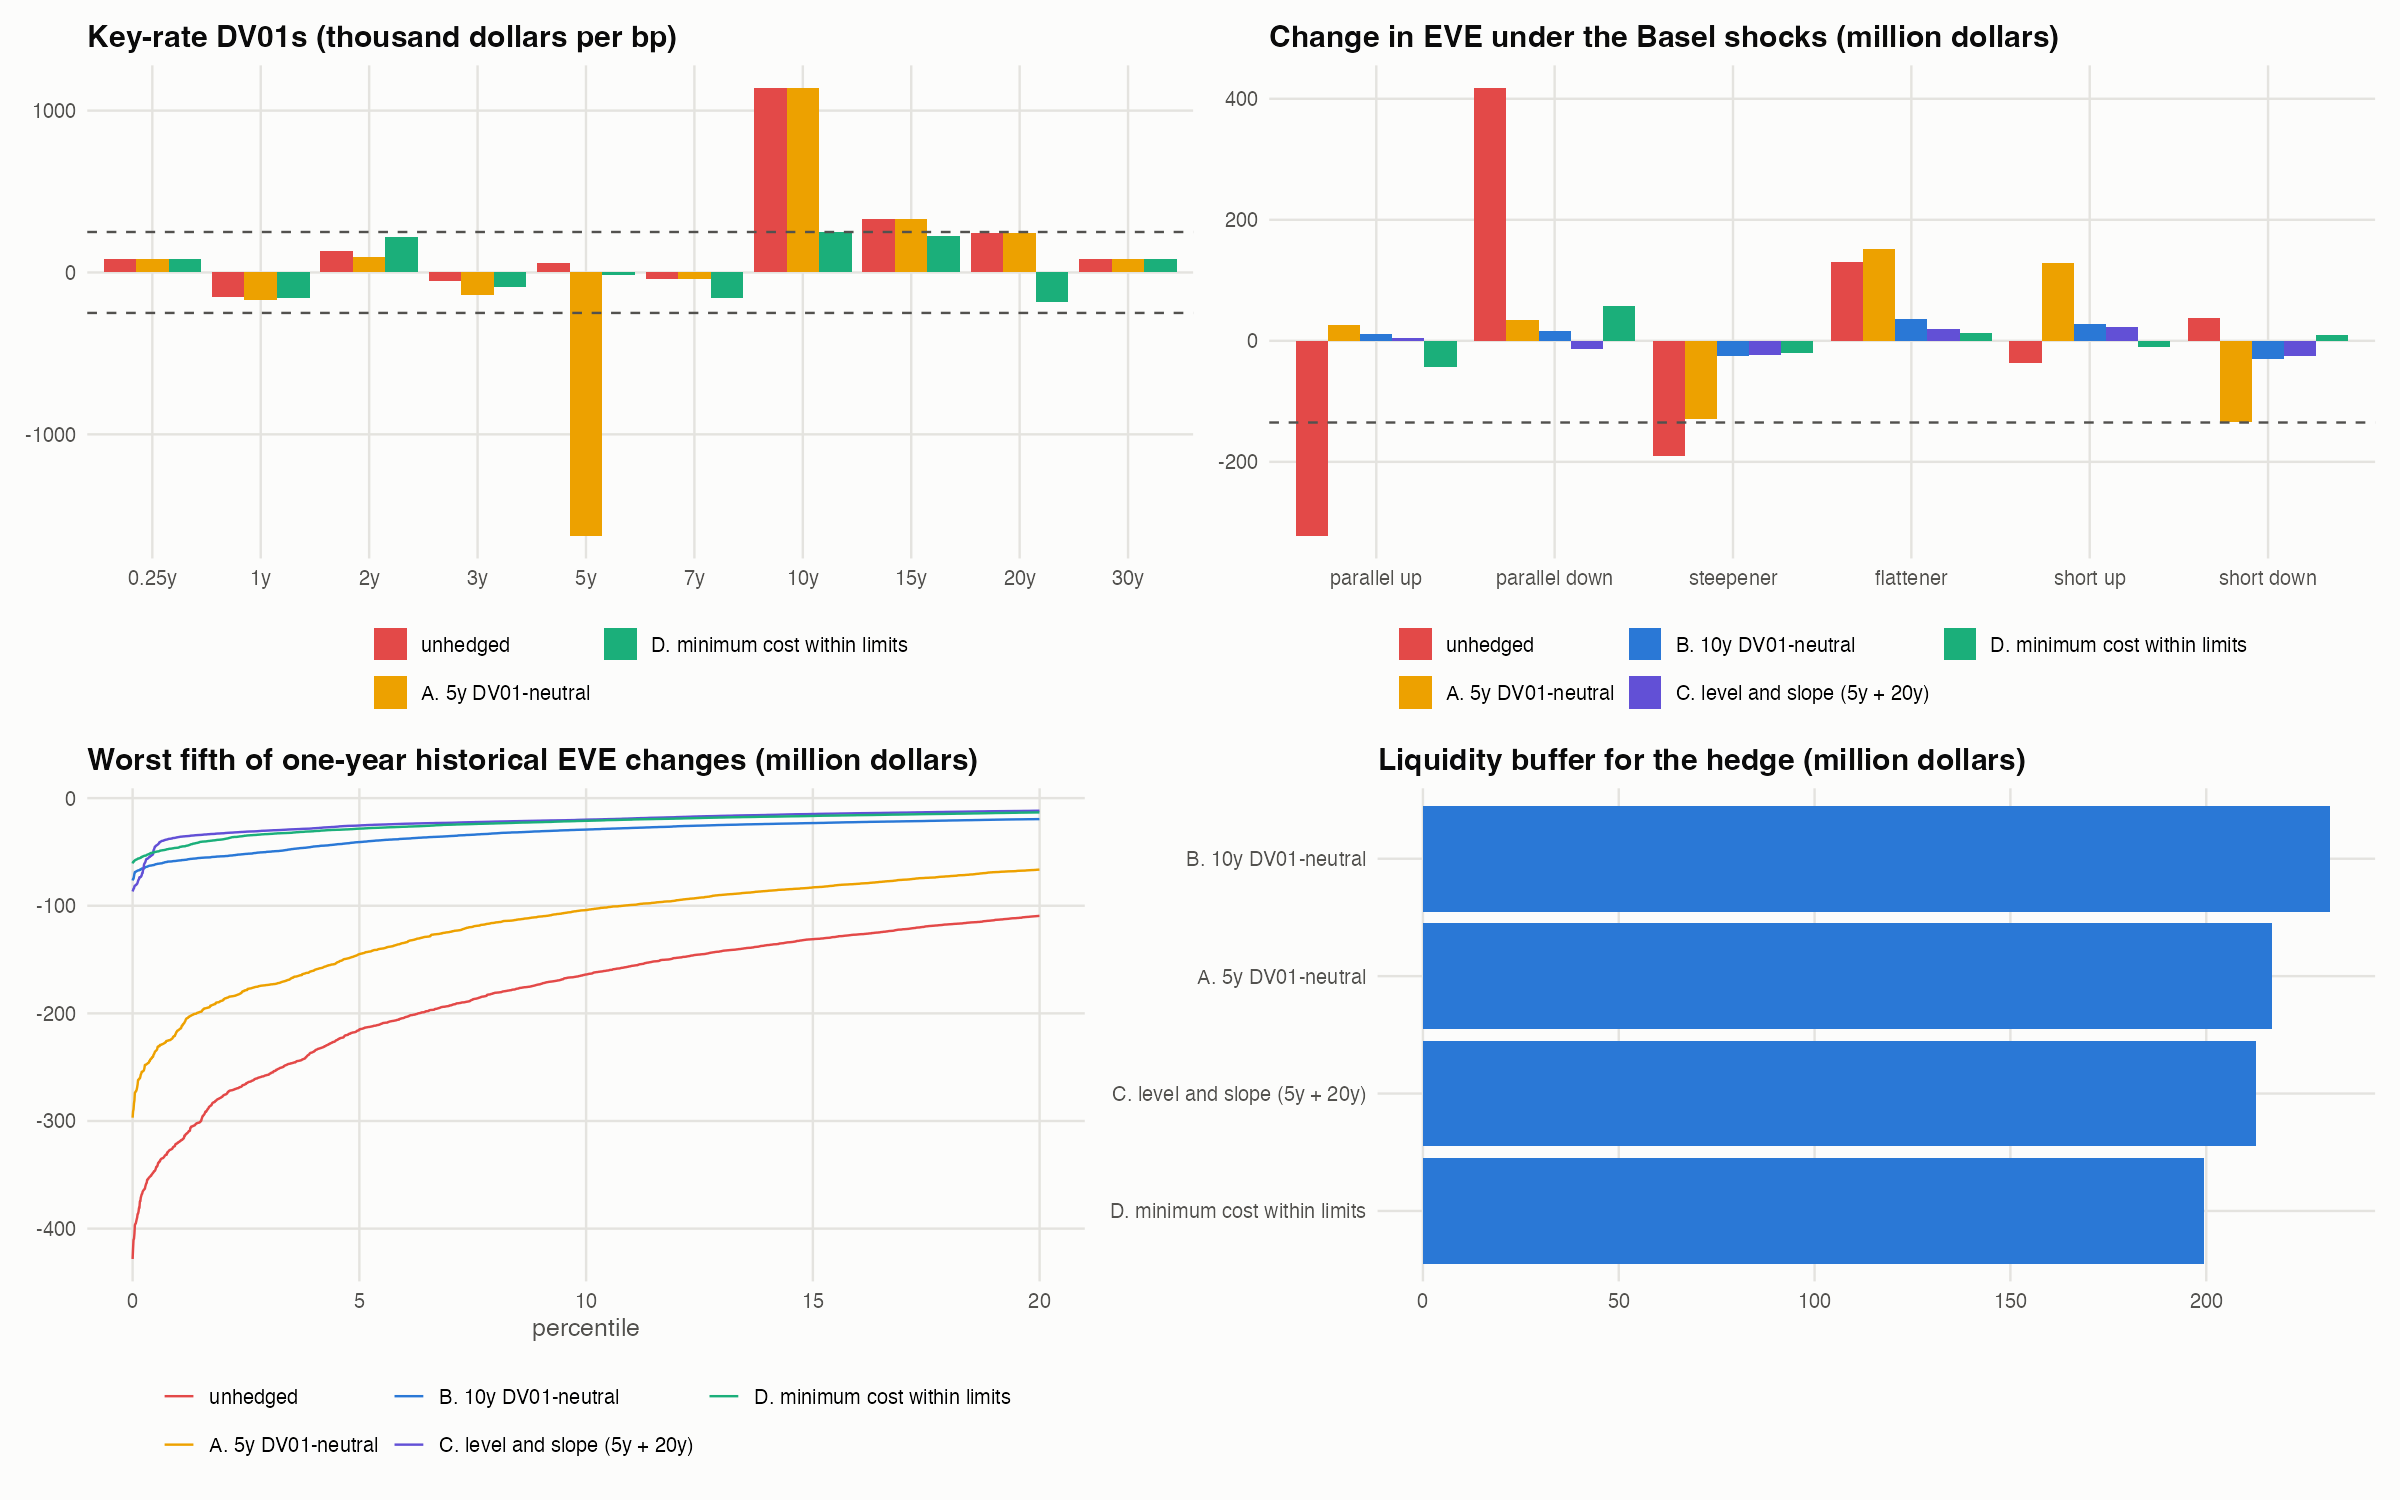

In [20]:
HCOL <- setNames(PALETTE[c(8, 4, 1, 7, 3)], names(HEDGES)); two_rows <- guides(fill = guide_legend(nrow = 2), colour = guide_legend(nrow = 2))
LL <- melt(data.table(bucket = factor(names(KR0), levels = names(KR0)), sapply(expo, identity)), id.vars = "bucket")
p1 <- ggplot(LL[variable %in% c("unhedged", "A. 5y DV01-neutral", "D. minimum cost within limits")], aes(bucket, value / 1e3, fill = variable)) +
  geom_col(position = "dodge") + geom_hline(yintercept = c(-1, 1) * LIM_BUCKET / 1e3, linetype = 2, colour = INK_2) +
  scale_fill_manual(values = HCOL) + two_rows + labs(title = "Key-rate DV01s (thousand dollars per bp)", x = NULL, y = NULL)
BL <- melt(BASEL[, c("hedge", SHOCKS), with = FALSE], id.vars = "hedge"); BL[, hedge := factor(hedge, levels = names(HEDGES))]
p2 <- ggplot(BL, aes(variable, value, fill = hedge)) + geom_col(position = "dodge") +
  geom_hline(yintercept = -OUTLIER * TIER1, linetype = 2, colour = INK_2) + scale_fill_manual(values = HCOL) + two_rows +
  labs(title = "Change in EVE under the Basel shocks (million dollars)", x = NULL, y = NULL)
HL <- melt(data.table(HIST)[, lapply(.SD, function(x) sort(x))][, q := seq(0, 1, length.out = .N)], id.vars = "q")
p3 <- ggplot(HL[q <= 0.2], aes(q * 100, value, colour = variable)) + geom_line() + scale_colour_manual(values = HCOL) + two_rows +
  labs(title = "Worst fifth of one-year historical EVE changes (million dollars)", x = "percentile", y = NULL)
p4 <- ggplot(LIQ, aes(reorder(hedge, `liquidity buffer (million)`), `liquidity buffer (million)`)) + geom_col(fill = PALETTE[1]) + coord_flip() +
  labs(title = "Liquidity buffer for the hedge (million dollars)", x = NULL, y = NULL)
show_fig((p1 + p2) / (p3 + p4), "01_key_rate_limits_and_liquidity", width = 16, height = 10)

In [21]:
QL <- QF[, .(date, target = target / 1e6, `XGBoost 99%` = xgb_0.99 / 1e6, `EWMA 99%` = ewma_0.99 / 1e6, `historical 99%` = hist_0.99 / 1e6)]
d1 <- ggplot(QL, aes(date)) + geom_point(aes(y = target), colour = INK_2, size = 0.5) +
  geom_line(aes(y = `XGBoost 99%`, colour = "XGBoost 99%")) + geom_line(aes(y = `EWMA 99%`, colour = "EWMA 99%")) + geom_line(aes(y = `historical 99%`, colour = "historical 99%")) +
  scale_colour_manual(values = PALETTE[c(2, 1, 4)]) + labs(title = "Hedge D: next-month margin outflow and 99% forecasts (million)", x = NULL, y = NULL)
d2 <- ggplot(HTAB[hedge != "unhedged"], aes(reorder(hedge, `bid-ask cost (dollars)`), `bid-ask cost (dollars)` / 1e3)) + geom_col(fill = PALETTE[4]) + coord_flip() +
  labs(title = "Bid-ask cost of the hedge (thousand dollars)", x = NULL, y = NULL)
dash <- (d1 | d2) + plot_annotation(title = "Key-rate limits and the liquidity cost of hedging")
save_fig(dash, "dashboard", width = 18, height = 6)
cat("Dashboard saved: outputs/dashboard.png\n")

Dashboard saved: outputs/dashboard.png


## 10. Reading the results and limitations

**The book.** On today's curve the stylised balance sheet has an EVE of 1,849 million dollars and an aggregate DV01 of +1.83 million dollars per bp. Mortgages and the 10-year Treasury bonds put +1.14 million per bp in the 10-year bucket and +0.65 million at 15 to 30 years. Core deposits and senior debt offset most of the 5-year loans and leave small short positions at 1, 3 and 7 years. Unhedged, a 200 bp parallel rise costs 322.6 million dollars, 35.8% of Tier 1 capital, more than twice the outlier threshold.

**A, B, C and D.**

- **A. Paying fixed on 4.1 billion of 5-year swaps** brings the aggregate DV01 to zero for 183,000 dollars of bid-ask. The aggregate limit is met, and so is the Basel test, but only just: the worst shock (short down) costs 14.9% of Tier 1. The key-rate view shows why it is fragile: −1.63 million per bp at 5 years against +1.14 million at 10 years. The 1% one-year historical loss is 216 million dollars (24% of Tier 1), the worst is 297 million (the year to March 2008), and 6% of historical years are worse than the worst Basel shock. A meets every rule that only looks at the total and fails every rule that looks inside it.
- **B. Moving the same DV01 to the 10-year swap** cuts the worst Basel loss to 30 million and the 1% historical loss to 58 million. It costs more (274,000 dollars), still breaches the 10-year bucket and the curvature limit, and 9.7% of historical years are worse than its worst Basel shock: the six shocks understate the risk of a book whose exposures cancel exactly on those shapes.
- **C. Neutralising level and slope** with 5- and 20-year swaps gives the smallest Basel loss (2.7% of Tier 1) and a 1% historical loss of 36 million. It is the most expensive (333,000 dollars) and leaves +0.98 million per bp in the 10-year bucket, offset at 5 and 20 years. Two-factor neutrality does not stop a 10-year-specific move: in the year to November 2008 it lost 87 million.
- **D. The linear programme** receives fixed on 2-year swaps and pays on 10- and 20-year swaps (2.4 billion of notional, 298,000 dollars of bid-ask). It is the only hedge that meets all four limit structures at once. Its worst Basel shock is 4.9% of Tier 1, its 1% one-year historical loss is 46 million and its worst year 61 million. Every limit binds somewhere: aggregate DV01, the 10-year bucket and the third principal component sit exactly at their limits.

**The liquidity bill.** The hedges remove most of the economic risk but create a cash risk the book did not have:

- **Initial margin** is 84 to 104 million dollars.
- **Variation margin:** the 99% month-ahead outflow is 109 to 128 million, so the liquidity buffer needed is 200 to 232 million dollars, 22% to 26% of Tier 1. The worst three-month outflow (the rally that ended in April 1986) is 364 to 445 million.
- **Hedge D:** in 130 of 493 months the swaps paid out more than 25 million dollars. In those months the hedged loans and deposits gained about as much in economic value (113% of the outflow at first order), but that gain is not cash.

The choice is therefore not between risk and no risk. Compared with no hedge, hedge D cuts the 1% one-year EVE loss from 320 to 46 million dollars. In exchange it needs about 200 million of liquid assets set aside and 0.3 million of trading cost. Hedge A ties up similar collateral and leaves five times the tail risk.

**Forecasting margin calls.** For hedge D's next-month margin outflow, over 382 monthly forecasts since 1995:

- **Historical five-year quantile:** at 99% it has 4 exceptions against 3.8 expected (Kupiec p 0.93).
- **EWMA with a normal quantile:** 6 exceptions (p 0.30) and the lowest pinball loss.
- **XGBoost:** 12 exceptions (p 0.001), and 57 at 95% against 19.1 expected. Its forecasts are too narrow.

The SHAP values lean on the level and slope of the curve and the funds rate, which set the drift of rates rather than the size of a bad month. For sizing a liquidity buffer, the simple volatility and historical rules are better calibrated. The latest XGBoost 99% forecast, 51 million dollars, is below both benchmarks and should not be used on its own.

**Limitations.**

- **The balance sheet is synthetic.** It is stylised, with fixed coupons, a constant 8% mortgage prepayment rate and a behavioural deposit profile, all of which a real ALM model would estimate.
- **Hedge pricing is simplified.** Swaps are priced on the Treasury zero curve, ignoring swap spreads and the SOFR basis. Their bid-ask spreads are assumptions.
- **EVE is static.** It discounts contractual cash flows with commercial margins on the risk-free curve; there is no earnings-at-risk view and no balance-sheet growth.
- **Margin is approximate.** Initial margin is a historical VaR proxy, not a clearing house's model. Variation margin is first order and ignores interest on collateral.
- **Limits are illustrative.** Limit levels and the principal-component limits are illustrative, and the post-shock floor follows the Basel formula.
- **Historical scenarios overlap.** The one-year windows overlap, so their quantiles rest on about 40 independent years.

In [22]:
fwrite(LADDER, file.path(OUT_DIR, "key_rate_ladder.csv"))
fwrite(HTAB, file.path(OUT_DIR, "hedges.csv"))
fwrite(BASEL, file.path(OUT_DIR, "basel_eve_shocks.csv"))
fwrite(HSTAT, file.path(OUT_DIR, "historical_eve.csv"))
fwrite(LIMITS, file.path(OUT_DIR, "limit_compliance.csv"))
fwrite(LIQ, file.path(OUT_DIR, "hedge_liquidity.csv"))
fwrite(DEC, file.path(OUT_DIR, "treasury_decision.csv"))
fwrite(QEV, file.path(OUT_DIR, "margin_forecast_evaluation.csv"))
fwrite(SHAP, file.path(OUT_DIR, "xgboost_shap.csv"))
cat("Outputs written:", paste(sort(list.files(OUT_DIR)), collapse = ", "), "\n")

Outputs written: 01_key_rate_limits_and_liquidity.png, basel_eve_shocks.csv, dashboard.png, hedge_liquidity.csv, hedges.csv, historical_eve.csv, key_rate_ladder.csv, limit_compliance.csv, margin_forecast_evaluation.csv, treasury_decision.csv, xgboost_shap.csv 


## References

- Board of Governors of the Federal Reserve System. *The U.S. Treasury yield curve: 1961 to the present* (feds200628.csv: Svensson parameters, daily).
- Federal Reserve Bank of St. Louis. *FRED: effective federal funds rate (DFF).*
- Basel Committee on Banking Supervision (2016). *Interest rate risk in the banking book.* Bank for International Settlements.
- Basel Committee on Banking Supervision (2019). *Basel Framework, SRP31: Interest rate risk in the banking book.* Bank for International Settlements.
- European Banking Authority (2022). *Guidelines on the management of interest rate risk and credit spread risk arising from non-trading book activities* (EBA/GL/2022/14).
- Gürkaynak, R. S., B. Sack, and J. H. Wright (2007). The U.S. Treasury yield curve: 1961 to the present. *Journal of Monetary Economics*, 54(8), 2291–2304.
- Ho, T. S. Y. (1992). Key rate durations: Measures of interest rate risks. *Journal of Fixed Income*, 2(2), 29–44.
- Litterman, R., and J. Scheinkman (1991). Common factors affecting bond returns. *Journal of Fixed Income*, 1(1), 54–61.
- Bessis, J. (2015). *Risk Management in Banking*, 4th edition. Wiley.
- Choudhry, M. (2018). *The Moorad Choudhry Anthology: Past, Present and Future Principles of Banking and Finance.* Wiley.
- Basel Committee on Banking Supervision and International Organization of Securities Commissions (2020). *Margin requirements for non-centrally cleared derivatives.* Bank for International Settlements.
- Bank for International Settlements, CPMI (2022). *Review of margining practices.*
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *Journal of Derivatives*, 3(2), 73–84.
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review*, 39(4), 841–862.
- Chen, T., and C. Guestrin (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD Conference*, 785–794.